# Q04 - Best-First vs Hill Climbing, Expanding Search and Action Space

Same code as `q04_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q4 - Best-first vs hill climbing, expanding search + action space, convergence control.

Part A: Diagram 3. Control convergence speed with a step size that differs at A, B and C,
        and compare it with fixed steps.
Part B: the Q3 airport. Add two new operations (f, g) and compare hill climbing with
        best-first search on the old (a-e) and the expanded (a-g) action space.
"""
import heapq
import math
import os
import random

import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


# ---------------- Part A: Diagram 3, convergence speed ----------------
def f(x: float) -> float:
    """The hill of Diagram 3: foot A on the left, slope B, peak C at x = 6."""
    return 5 + 80 * math.exp(-((x - 6) ** 2) / (2 * 1.6 ** 2))


def slope(x: float) -> float:
    return (f(x + 0.01) - f(x - 0.01)) / 0.02


def climb(x: float, step: float, adaptive: bool = False, max_moves: int = 200):
    """Hill climbing on Diagram 3. Adaptive: big step at A, medium at B, shrinking at C."""
    path, steps, zones, overshot = [x], [], [], False
    for _ in range(max_moves):
        if adaptive and not overshot:
            zone, step = ("A", 1.2) if abs(slope(x)) < 3 else ("B", 0.6)
        else:
            zone = "C" if adaptive else "-"
        best = max((x + step, x - step), key=f)
        if f(best) > f(x):  # uphill move found
            x = best
            path.append(x)
            steps.append(step)
            zones.append(zone)
        elif adaptive and step > 0.01:  # we stepped over the peak: slow down (zone C)
            overshot, step = True, step / 2
        else:
            break
    return x, path, steps, zones


A_START, PEAK = 1.3, 6.0
runs = {"fixed small step 0.1": climb(A_START, 0.1), "fixed big step 1.5": climb(A_START, 1.5),
        "adaptive A/B/C": climb(A_START, 1.2, adaptive=True)}
print(f"PART A  Diagram 3 convergence (start A at x = {A_START}, peak C at x = {PEAK:.2f},"
      f" f = {f(PEAK):.2f})")
print(f"  {'strategy':<22}| moves | final x | f(x)  | gap to peak")
for name, (x, path, _, _) in runs.items():
    print(f"  {name:<22}| {len(path) - 1:>5} | {x:7.3f} | {f(x):5.2f} | {f(PEAK) - f(x):.3f}")
_, _, ad_steps, ad_zones = runs["adaptive A/B/C"]
for z in "ABC":
    used = [s for s, zz in zip(ad_steps, ad_zones) if zz == z]
    print(f"  adaptive step in zone {z}: {', '.join(f'{s:g}' for s in used)}")

# ---------------- Part B: the Q3 airport with a larger action space ----------------
rng = random.Random(3)  # same 10 travellers as in Q3
TRAVELLERS = [tuple(rng.uniform(0.2, 1.0) for _ in range(4)) for _ in range(10)]


def used_space(s: tuple) -> float:
    return 3 * s[0] + 1.5 * s[1] + s[4] + 12


def score(s: tuple) -> float:
    gates, counters, area, shop, waiting = s
    crowd = max(0.0, 1.6 * gates - waiting) * 0.9
    wait_min = 6 + 260 / gates + 150 / min(counters, 14) + crowd
    wait_score = min(1.0, max(0.0, (50 - wait_min) / 40))
    seats, shop_fit, queue_fit = min(1.0, waiting / (2 * gates)), 1 - abs(shop - 3) / 3, \
        min(1.0, counters / 12)
    senior = 0.4 * seats + 0.3 * shop_fit + 0.3 * queue_fit - 0.015 * max(0, gates - 16)
    likes = (wait_score, seats, shop_fit, queue_fit)
    votes = sum(sum(p * v for p, v in zip(t, likes)) / sum(t) > 0.62 for t in TRAVELLERS)
    useful = 3 * min(gates, 18) + 1.5 * min(counters, 12) + min(waiting, 2 * gates) + 12
    return round(100 * (0.30 * votes / 10 + 0.30 * wait_score + 0.15 * useful / area
                        + 0.25 * senior), 2)


def legal(s: tuple) -> bool:
    return s[0] >= 4 and s[1] >= 2 and 0 <= s[3] <= 4 and s[4] >= 4 and used_space(s) <= s[2]


OLD = {  # the five legal actions of Q3
    "a": lambda s: (s[0] + 1, s[1], s[2], s[3], s[4]),
    "b": lambda s: (s[0], s[1] + 1, s[2], s[3], s[4]),
    "c": lambda s: (s[0], s[1], s[2] - 6, s[3], s[4]),
    "d+": lambda s: (s[0], s[1], s[2], s[3] + 1, s[4]),
    "d-": lambda s: (s[0], s[1], s[2], s[3] - 1, s[4]),
    "e+": lambda s: (s[0], s[1], s[2], s[3], s[4] + 4),
    "e-": lambda s: (s[0], s[1], s[2], s[3], s[4] - 4),
}
NEW = dict(OLD, **{
    "f": lambda s: (s[0] + 2, s[1], s[2] + 20, s[3], s[4] + 8),  # f: pier = floor, 2 gates, lounge
    "g": lambda s: (s[0] + 1, s[1], s[2], s[3], s[4] + 4),  # g: gate + seats in one move
})


def hill_climb(start: tuple, actions: dict) -> tuple:
    current, evaluated, used = start, 1, []
    while True:
        options = [(score(n), name, n) for name, act in actions.items() if legal(n := act(current))]
        evaluated += len(options)
        best_score, name, best = max(options, key=lambda o: o[0])  # first best move wins ties
        if best_score <= score(current):
            return current, evaluated, used
        current = best
        used.append(name)


def best_first(start: tuple, actions: dict, budget: int = 400) -> tuple:
    """Best-first keeps every generated design in OPEN, so it can leave a local peak."""
    tie, best, expanded = 0, start, 0
    frontier, seen = [(-score(start), tie, start)], {start}
    while frontier and expanded < budget:
        _, _, s = heapq.heappop(frontier)  # most promising design anywhere in OPEN
        expanded += 1
        best = max(best, s, key=score)
        for act in actions.values():
            n = act(s)
            if legal(n) and n not in seen:
                seen.add(n)
                tie += 1
                heapq.heappush(frontier, (-score(n), tie, n))
    return best, len(seen)


def reachable(start: tuple, actions: dict, depth: int) -> int:
    layer, seen = {start}, {start}
    for _ in range(depth):
        layer = {n for s in layer for a in actions.values() if legal(n := a(s))} - seen
        seen |= layer
    return len(seen)


BLUEPRINT = (10, 6, 100, 0, 14)
print("PART B  Q3 airport + f: new pier (+20 floor, +2 gates, +8 seats), g: gate + 4 seats")
print(f"  designs reachable in 6 moves: a-e = {reachable(BLUEPRINT, OLD, 6)},"
      f" a-g = {reachable(BLUEPRINT, NEW, 6)}")
print(f"  {'method':<22}| actions | designs scored | best score | design (gates, counters, area)")
results = {}
for label, acts in (("a-e", OLD), ("a-g", NEW)):
    hc, hc_eval, hc_path = hill_climb(BLUEPRINT, acts)
    bf, bf_eval = best_first(BLUEPRINT, acts)
    results[label] = (hc, bf, hc_path)
    for method, s, n in (("hill climbing", hc, hc_eval), ("best-first (400)", bf, bf_eval)):
        print(f"  {method:<22}| {label:<7} | {n:>14} | {score(s):10.2f} | {s[0]}, {s[1]}, {s[2]}")
print("  hill climbing a-g, moves in order:", " ".join(results["a-g"][2]))

# ---------------- charts ----------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
xs = [i / 50 for i in range(0, 551)]
a1.plot(xs, [f(x) for x in xs], color="#c2410c", lw=2.2)
_, ad_path, _, _ = runs["adaptive A/B/C"]
colors = {"A": "#3a6ea5", "B": "#2a9d8f", "C": "#d98e04"}
for (x0, x1), z in zip(zip(ad_path, ad_path[1:]), ad_zones):
    a1.annotate("", xy=(x1, f(x1)), xytext=(x0, f(x0)),
                arrowprops=dict(arrowstyle="-|>", color=colors[z], lw=1.6))
for label, x, off in (("A", A_START, (-14, 8)), ("B", 3.7, (-16, 6)), ("C", PEAK, (10, -4))):
    a1.annotate(label, (x, f(x)), xytext=off, textcoords="offset points", fontsize=12,
                fontweight="bold")
for z, c in colors.items():
    a1.plot([], [], color=c, lw=2, label={"A": "zone A: big step 1.2", "B": "zone B: step 0.6",
                                          "C": "zone C: step halves"}[z])
a1.set_ylim(0, 95)
a1.set_xlabel("design variable x")
a1.set_ylabel("score f(x)")
a1.set_title("Diagram 3 with an adaptive step: fast at A, steady at B, careful at C")
a1.legend(loc="upper left", fontsize=8.5)
for name, (_, path, _, _) in runs.items():
    a2.plot([f(x) for x in path], marker="o", ms=3, label=f"{name} ({len(path) - 1} moves)")
a2.set_xlabel("move number")
a2.set_ylabel("score f(x)")
a2.set_title("Convergence speed")
a2.legend(fontsize=8.5, loc="lower right")
fig.tight_layout()
fig.savefig("images/q04_chart1_diagram3_convergence.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels, vals, cols = [], [], []
for act_label, (hc, bf, _) in results.items():
    for method, s in (("hill climbing", hc), ("best-first", bf)):
        labels.append(f"{method}\nactions {act_label}")
        vals.append(score(s))
        cols.append("#a8c5e2" if act_label == "a-e" else "#2a9d8f")
bars = ax.bar(labels, vals, color=cols)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylim(min(vals) - 6, max(vals) + 3)
ax.set_ylabel("best airport score C")
ax.set_title("Only the bigger action space (a-g) escapes 79.40; best-first adds a bit more")
fig.tight_layout()
fig.savefig("images/q04_chart2_airport_actions.png")
plt.close(fig)
print("charts saved to images/")


PART A  Diagram 3 convergence (start A at x = 1.3, peak C at x = 6.00, f = 85.00)
  strategy              | moves | final x | f(x)  | gap to peak
  fixed small step 0.1  |    47 |   6.000 | 85.00 | 0.000
  fixed big step 1.5    |     3 |   5.800 | 84.38 | 0.623
  adaptive A/B/C        |    12 |   5.997 | 85.00 | 0.000
  adaptive step in zone A: 1.2
  adaptive step in zone B: 0.6, 0.6, 0.6, 0.6, 0.6, 0.6
  adaptive step in zone C: 0.15, 0.075, 0.0375, 0.01875, 0.009375
PART B  Q3 airport + f: new pier (+20 floor, +2 gates, +8 seats), g: gate + 4 seats
  designs reachable in 6 moves: a-e = 650, a-g = 1765
  method                | actions | designs scored | best score | design (gates, counters, area)
  hill climbing         | a-e     |            117 |      79.40 | 14, 13, 100
  best-first (400)      | a-e     |            875 |      79.40 | 14, 13, 100
  hill climbing         | a-g     |            158 |      82.49 | 17, 14, 120
  best-first (400)      | a-g     |           1856 |      

charts saved to images/


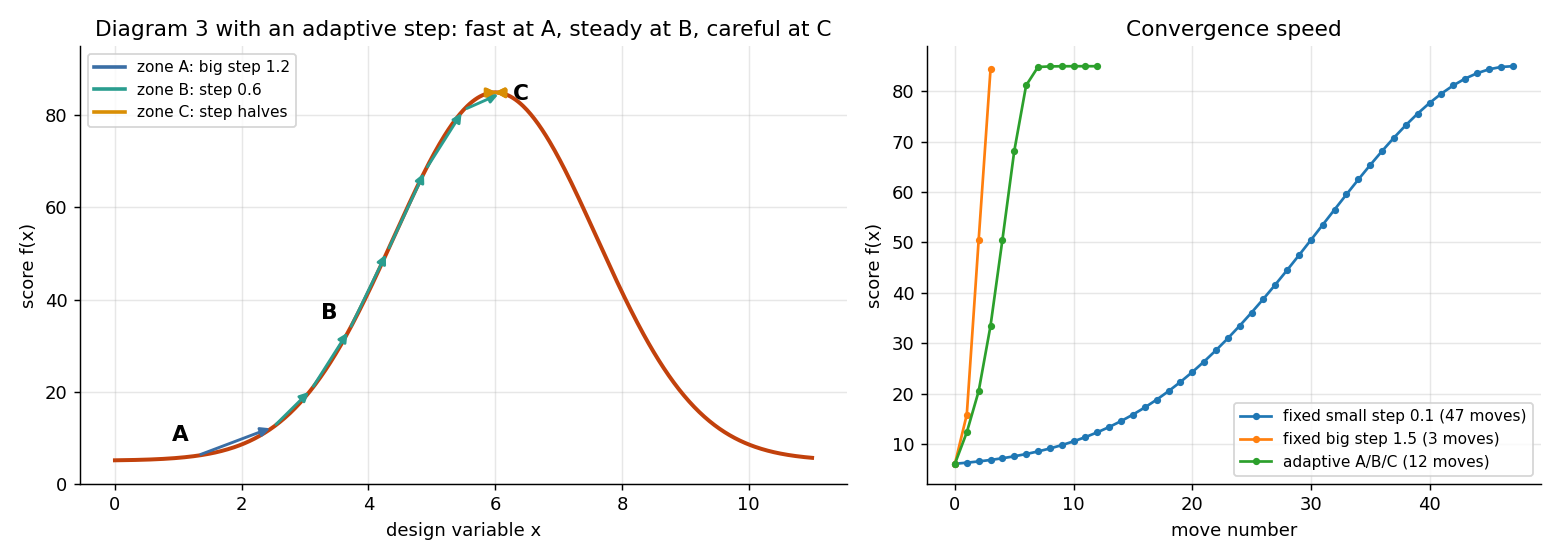

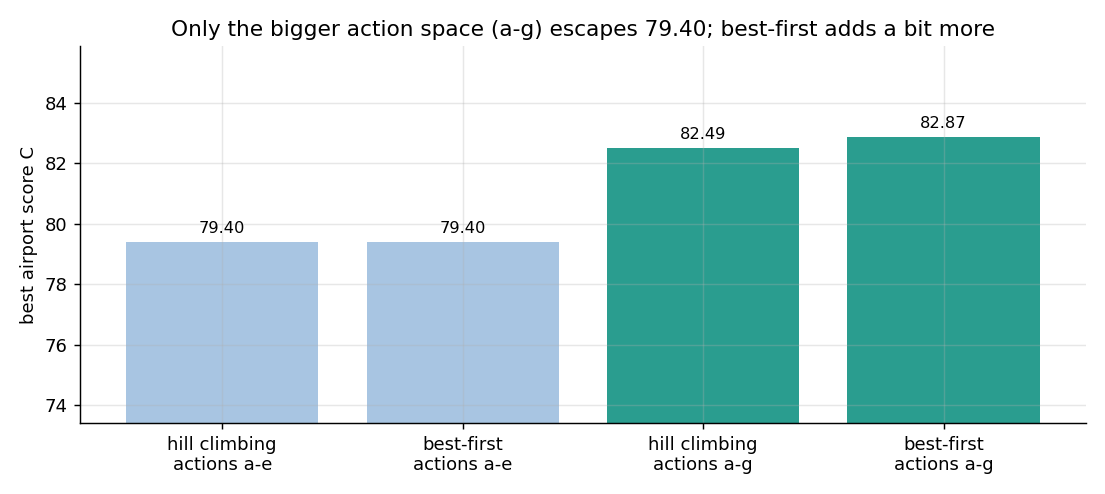

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q04_chart*.png')):
    display(Image(p))